In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path(".").resolve().parent / "pipelines" / "portland"))

In [2]:
import numpy as np
from matplotlib.axes import Axes
from typing import Optional, Dict, List, Tuple, Union
from matplotlib.colors import Colormap, TwoSlopeNorm
import matplotlib.pyplot as plt
import seaborn as sns

def _add_text_to_heatmap(
    *,
    heatmap: Axes,
    n_decimals_to_display: int,
    matrix: np.ndarray,
    cell_font_size: Optional[int] = None,
) -> Axes:
    """
    Adds the text values to the heatmap cells. This function dynamically determines
    the font size based on the number of cells in the figure, the figure size, and
    the length of the numbers to ensure readability.

    Args:
        heatmap (matplotlib.axes.Axes): The matplotlib axis containing the heatmap.
        n_decimals_to_display (int): The number of decimal places to display for the values
            in the heatmap.
        matrix (np.ndarray): A 2D numpy array containing the data to be plotted.
        cell_font_size (Optional[int]): The base font size to use for the cell values.
            If None, the font size will be dynamically determined.

    Returns:
        matplotlib.axes.Axes: The matplotlib axis containing the heatmap with the cell values
            and text values added.
    """
    nrows, ncols = matrix.shape
    quadmesh = heatmap.collections[0]

    max_chars = max(
        len(f"{val:.{n_decimals_to_display}f}") + (3 if val < 0 else 2)
        for val in matrix.flatten()
    )

    if cell_font_size is not None:
        font_size = cell_font_size
    else:
        fig = heatmap.get_figure()
        if fig:
            fig.canvas.draw()

            # ignoring mypy error, mypy not up to date with matplotlib get_renderer
            renderer = fig.canvas.get_renderer()  # type: ignore[attr-defined]

            # bounding box in display coords
            bbox = heatmap.get_window_extent(renderer=renderer)
            width_pts = bbox.width

            cell_width_pts = width_pts / ncols

            font_size = int(cell_width_pts / max_chars)

    for i in range(nrows):
        for j in range(ncols):
            val = matrix[i, j]
            txt = "N/A" if np.isnan(val) else f"{val:.{n_decimals_to_display}f}"
            txt = "inf" if np.isinf(val) else f"{val:.{n_decimals_to_display}f}"

            # Normalize the cell value between 0 and 1, then get the RGBA color
            norm_val = quadmesh.norm(val)
            r, g, b, _ = quadmesh.cmap(norm_val)

            # Simple brightness measure: average of R, G, B
            brightness = (r + g + b) / 3
            txt_color = "black" if brightness > 0.5 else "white"
            txt_color = "white" if np.isnan(val) else txt_color
            txt_color = "white" if np.isinf(val) else txt_color

            heatmap.text(
                j + 0.5,
                i + 0.5,
                txt,
                ha="center",
                va="center",
                color=txt_color,
                fontsize=font_size,
            )

    return heatmap


def _add_legend_to_heatmap(
    *,
    row_and_col_legends: Dict[str, str],
    ax: Axes,
    legend_font_size: float,
    legend_loc: str,
    legend_bbox_to_anchor: Tuple[float, float],
) -> Axes:
    """
    Adds a legend to a heatmap.

    Args:
        row_and_col_legends (Dict[str, str]): A dictionary mapping row and column labels to
            legend descriptions.
        ax (matplotlib.axes.Axes): The matplotlib axis to add the legend to.
        legend_font_size (float): The font size to use for the legend.
        legend_loc (str): The location to place the legend.
        legend_bbox_to_anchor (Tuple[float, float]): The bounding box to anchor the legend to.

    Returns:
        matplotlib.axes.Axes: The matplotlib axis containing with the updated legend.
    """
    proxy_artists = []
    proxy_labels = []

    if len(row_and_col_legends) != 0:
        for label, description in row_and_col_legends.items():
            patch = mpatches.Patch(color="white", label=f"{label}: {description}")
            proxy_artists.append(patch)
            proxy_labels.append(f"{label}: {description}")

    if proxy_artists:
        leg = ax.legend(
            handles=proxy_artists,
            labels=proxy_labels,
            loc=legend_loc,
            bbox_to_anchor=legend_bbox_to_anchor,
            fontsize=legend_font_size,
            ncol=len(proxy_labels) // 15 + 1,
            frameon=True,
            borderaxespad=0.0,
            handlelength=0,
            handletextpad=0,
            fancybox=True,
        )

        for item in leg.legend_handles:
            if item:
                item.set_visible(False)

    return ax

def matrix_heatmap(
    matrix: np.ndarray,
    *,
    ax: Optional[Axes] = None,
    show_cell_values: bool = True,
    n_decimals_to_display: int = 2,
    vmin: Optional[float] = None,
    vmax: Optional[float] = None,
    row_labels: Optional[List[str]] = None,
    row_label_rotation: Optional[float] = None,
    row_legend: Optional[dict[str, str]] = None,
    column_labels: Optional[List[str]] = None,
    column_label_rotation: Optional[float] = None,
    column_legend: Optional[dict[str, str]] = None,
    cell_color_map: Optional[Union[str, Colormap]] = None,
    cell_font_size: Optional[int] = None,
    cell_spacing: float = 0.5,
    cell_divider_color: str = "white",
    show_colorbar: bool = False,
    legend_font_size: float = 10.0,
    legend_location: str = "center left",
    legend_bbox_to_anchor: Tuple[float, float] = (1.03, 0.5),
) -> Axes:
    """
    Basic function for plotting a matrix as a heatmap.

    Args:
        matrix (np.ndarray): A 2D numpy array containing the data to be plotted.
        ax (matplotlib.axes.Axes, optional): The matplotlib axis to plot on. Defaults to None,
            in which case an axis is created.
        show_cell_values (bool): Whether to show the values of the cells in the heatmap. These
            values are shown in the center of each cell and are dynamically formatted to be
            human-readable.  Defaults to True.
        n_decimals_to_display (int): The number of decimal places to display for the values
            in the heatmap.  Defaults to 2.
        row_labels (Optional(List[str])): A list of strings containing the labels for the rows
            of the heatmap. Defaults to None.
        row_label_rotation (Optional(float)): The rotation to apply to the row labels.
            Defaults to None.
        row_legend (Optional(Dict[str, str])): A dictionary mapping row labels to legend
            descriptions. Defaults to None.
        column_labels (Optional(List[str])): A list of strings containing the labels for the
            columns of the heatmap. Defaults to None.
        column_label_rotation (Optional(float)): The rotation to apply to the column labels.
            Defaults to None.
        column_legend (Optional(Dict[str, str])): A dictionary mapping column labels to legend
            descriptions. Defaults to None.
        cell_color_map (Optional(Union[str, matplotlib.colors.Colormap])): The color map to use
            for the heatmap. Defaults to `PRGn` if the matrix contains negative values and
            `Greens` otherwise.
        cell_font_size (Optional(int)): The font size to use for the cell values. Defaults to
            None, which will then use dynamic font size based on the number of cells and the
            figure size.
        cell_spacing (float): The spacing between the cells in the heatmap. Defaults to 0.5.
        cell_divider_color (str): The color to use for the cell dividers for spacing cells.
            Defaults to "white".
        show_colorbar (bool): Whether to show the colorbar for the heatmap. Defaults to False.
        legend_font_size (float): The font size to use for the legend. Defaults to 10.0.
        legend_location (str): The location to place the legend. Defaults to "center left".
        legend_bbox_to_anchor (Tuple[float, float]): The bounding box to anchor the legend to.
            Defaults to (1.03, 0.5).

    Returns:
        matplotlib.axes.Axes: The matplotlib axis containing the heatmap.
    """

    if ax is None:
        _, ax = plt.subplots()

    row_and_col_legends = dict()
    if row_legend is not None:
        row_and_col_legends.update(row_legend)
    if column_legend is not None:
        row_and_col_legends.update(column_legend)

    ax.xaxis.set_ticks_position("top")
    ax.yaxis.set_ticks_position("left")

    vmin = vmin if vmin is not None else np.nanmin(matrix)
    vmax = vmax if vmax is not None else np.nanmax(matrix)
    norm: Union[TwoSlopeNorm, str, None] = (
        TwoSlopeNorm(vmin=vmin, vcenter=0.0, vmax=vmax) if (vmin < 0 < vmax) else None
    )

    if cell_color_map is None:
        if np.nanmin(matrix) < 0:
            cell_color_map = sns.color_palette("PRGn", as_cmap=True)
            norm = TwoSlopeNorm(
                vmin=np.nanmin(matrix), vcenter=0.0, vmax=np.nanmax(matrix)
            )
        else:
            cell_color_map = sns.color_palette("Greens", as_cmap=True)
            norm = "linear"

    heatmap = sns.heatmap(
        matrix,
        ax=ax,
        vmin=vmin,
        vmax=vmax,
        cmap=cell_color_map,
        norm=norm,
        fmt=f".{n_decimals_to_display}f",
        linewidths=cell_spacing,
        linecolor=cell_divider_color,
        cbar=show_colorbar,
        yticklabels=row_labels if row_labels is not None else False,
        xticklabels=column_labels if column_labels is not None else False,
    )

    plt.gca().set_facecolor("black")  # inf cells

    if show_cell_values:
        heatmap = _add_text_to_heatmap(
            heatmap=heatmap,
            n_decimals_to_display=n_decimals_to_display,
            matrix=matrix,
            cell_font_size=cell_font_size,
        )

    if len(row_and_col_legends) > 0:
        heatmap = _add_legend_to_heatmap(
            row_and_col_legends=row_and_col_legends,
            ax=heatmap,
            legend_font_size=legend_font_size,
            legend_loc=legend_location,
            legend_bbox_to_anchor=legend_bbox_to_anchor,
        )

    if column_label_rotation is not None:
        ax.set_xticklabels(
            ax.get_xticklabels(),
            rotation=column_label_rotation,
            ha="left",
            rotation_mode="anchor",
        )
    if row_label_rotation is not None:
        ax.set_yticklabels(
            ax.get_yticklabels(), rotation=row_label_rotation, rotation_mode="anchor"
        )

    return ax

In [3]:
print(sys.path)

['/home/peter/.local/share/uv/python/cpython-3.12.13-linux-x86_64-gnu/lib/python312.zip', '/home/peter/.local/share/uv/python/cpython-3.12.13-linux-x86_64-gnu/lib/python3.12', '/home/peter/.local/share/uv/python/cpython-3.12-linux-x86_64-gnu/lib/python3.12/lib-dynload', '', '/mnt/efs/h/Dropbox/MADLAB/papers/Quantitative_fairness/.venv/lib/python3.12/site-packages', '/mnt/efs/h/Dropbox/MADLAB/papers/Quantitative_fairness/pipelines/portland']


In [4]:
from votekit.matrices import boost_matrix
from votekit import RankProfile

In [5]:
focus_candidates = {
    "D1": {
        1: [
            'Candace Avalos',
            'Steph Routh',
            'Jamie Dunphy',
            'Timur Ender',
        ],
        2: [
            'Loretta Smith',
            'Terrence Hayes',
            'Noah Ernst'
        ]
    },
    "D2": {
        1: [
            "Elana Pirtle-Guiney",
            "Dan Ryan",
            "Tiffani Penson",
            "Mariah Hudson"
        ],
        2: [
            "Michelle DePass",
            "Sameer Kanal",
            "Nat West",
            "Jonathan Tasini",
            "Marnie Glickman"
        ]
    },
    "D3": {
        1: [
            "Angelita Morillo",
            "Tiffany Koyama Lane",
        ],
        2: [
            "Steve Novick",
            "Jesse Cornett",
            "Rex Burkholder"  
        ]
    },
    "D4": {
        1: [
            "Olivia Clark",
            "Eric Zimmerman",
            "Eli Arnold",
            "Bob Weinstein",
        ],
        2: [
            "Mitch Green",
            "Sarah Silkie",
            "Chad Lykins",
            "Lisa Freeman"
        ]
    }
}

In [6]:
from votekit import RankProfile
from votekit.elections import FastSTV
from votekit.cleaning import remove_and_condense_rank_profile
from votekit.matrices import boost_matrix
from votekit.utils import mentions
import random
import argparse
import numpy as np
from pathlib import Path
import sys


def load_and_project(profile_number: int):
    """Load in the profile and project it to the viable candidates.

    Args:
        profile_number (int): The number of the profile to load and project.
    """

    profile = RankProfile.from_csv(
        f"../data/Portland_D{profile_number}_cleaned_votekit.csv"
    )
    candidates = list(profile.candidates)

    elec = FastSTV(profile, m=3)  # ty: ignore
    mentions_dict = mentions(profile)  # ty: ignore

    non_viable_cands = [
        cand for cand in candidates if mentions_dict[cand] < elec.threshold
    ]

    projected_profile = remove_and_condense_rank_profile(non_viable_cands, profile)  # ty: ignore
    projected_boost = boost_matrix(
        projected_profile, candidates=list(projected_profile.candidates)
    )
    projected_boost = np.nan_to_num(projected_boost)

    return projected_profile, projected_boost

In [7]:
from votekit.elections import FastSTV
from votekit import RankProfile


district = "D3"

profile = RankProfile.from_csv(f"../data/Portland_{district}_cleaned_votekit.csv")

mentions_dict = mentions(profile)

elec = FastSTV(profile, m=3)
non_viable_cands = [
    cand for cand in profile.candidates if mentions_dict[cand] < elec.threshold
]

projected_profile = remove_and_condense_rank_profile(non_viable_cands, profile)  # ty: ignore

focus_cands = sum([l for l in focus_candidates[district].values()], [])
focus_cand_last = [" ".join(c.split()[1:]) for c in focus_cands]
M, conditional, unconditional = boost_matrix(projected_profile, candidates = focus_cands)

In [8]:
projected_profile.candidates

('Steve Novick',
 'Angelita Morillo',
 'Rex Burkholder',
 'Tiffany Koyama Lane',
 'Jesse Cornett')

In [11]:
conditional

array([[0.        , 0.75444677, 0.59377991, 0.63815622, 0.63507755],
       [0.72900562, 0.        , 0.53499775, 0.53249235, 0.52756093],
       [0.64020473, 0.59695701, 0.        , 0.71543705, 0.71562979],
       [0.42195168, 0.36437353, 0.43874661, 0.        , 0.5446736 ],
       [0.39240053, 0.33734415, 0.41010764, 0.50898318, 0.        ]])

In [ ]:
unconditional

array([[0.        , 0.61453331, 0.61453331, 0.61453331, 0.61453331],
       [0.59381027, 0.        , 0.59381027, 0.59381027, 0.59381027],
       [0.66258074, 0.66258074, 0.        , 0.66258074, 0.66258074],
       [0.40633211, 0.40633211, 0.40633211, 0.        , 0.40633211],
       [0.37970669, 0.37970669, 0.37970669, 0.37970669, 0.        ]])

In [13]:
M2, conditional2, unconditional2 = boost_matrix(profile, candidates = focus_cands)

In [14]:
conditional2

array([[0.        , 0.75444677, 0.59377991, 0.63815622, 0.63507755],
       [0.72900562, 0.        , 0.53499775, 0.53249235, 0.52756093],
       [0.64020473, 0.59695701, 0.        , 0.71543705, 0.71562979],
       [0.42195168, 0.36437353, 0.43874661, 0.        , 0.5446736 ],
       [0.39240053, 0.33734415, 0.41010764, 0.50898318, 0.        ]])

In [15]:
unconditional2

array([[0.        , 0.56281711, 0.56281711, 0.56281711, 0.56281711],
       [0.54383802, 0.        , 0.54383802, 0.54383802, 0.54383802],
       [0.60682109, 0.60682109, 0.        , 0.60682109, 0.60682109],
       [0.37213713, 0.37213713, 0.37213713, 0.        , 0.37213713],
       [0.34775238, 0.34775238, 0.34775238, 0.34775238, 0.        ]])

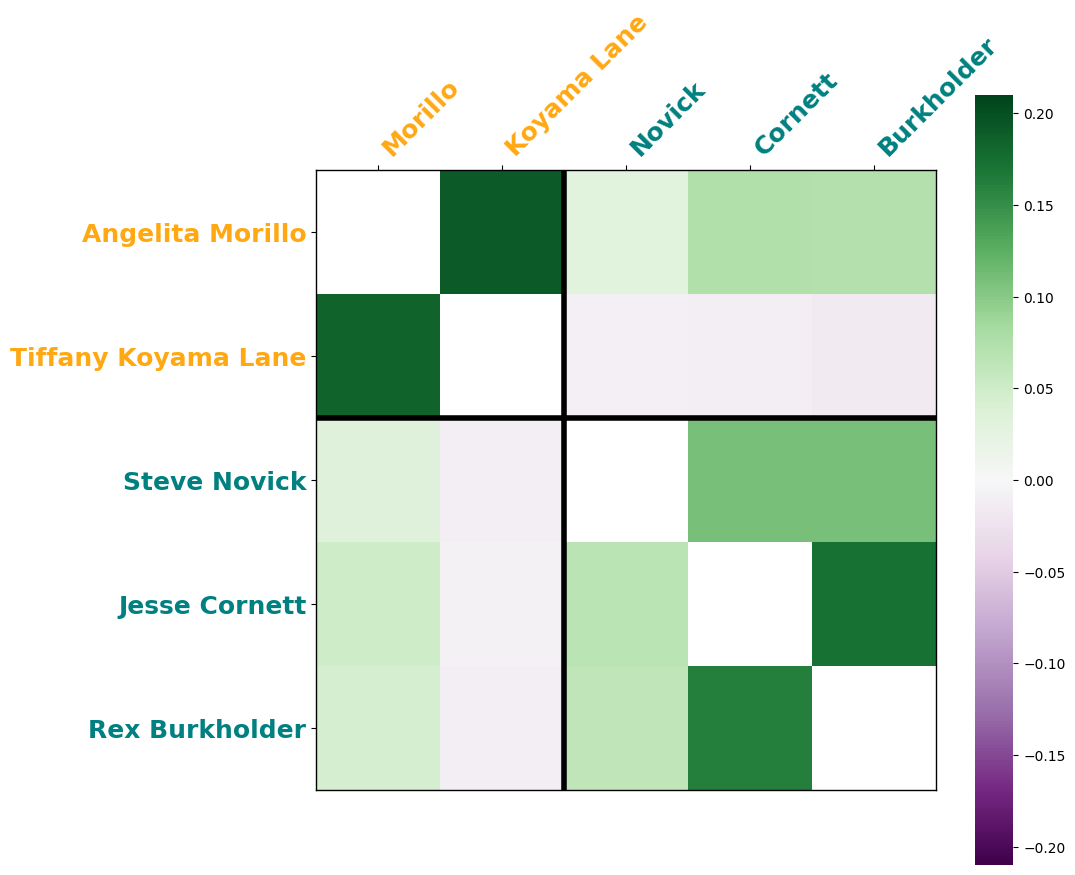

In [ ]:
import matplotlib.pyplot as plt

_, ax = plt.subplots(figsize=(10, 10))

ax = matrix_heatmap(
    M2, 
    ax=ax,
    vmin = -0.21,
    vmax = 0.21,
    cell_color_map = "PRGn",
    show_cell_values=False,
    cell_spacing=0,
    show_colorbar=False,
)

ax.set_aspect("equal")

plt.gca().set_facecolor("white")  # inf cells

tick_locations = [x + 0.5 for x in range(len(focus_cands))]

ax.set_xticks(tick_locations, minor=False)
ax.set_xticklabels(focus_cand_last, rotation=90)
ax.set_yticks(tick_locations, minor=False)
ax.set_yticklabels(focus_cands)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1)


slate1_cands = focus_candidates[district][1]
slate1_cands_last = [" ".join(c.split()[1:]) for c in slate1_cands]

ax.axvline(x=len(slate1_cands), color='black', linewidth=4)
ax.axhline(y=len(slate1_cands), color='black', linewidth=4)

for label in ax.get_yticklabels():
    if label.get_text() in slate1_cands:
        label.set_color("#FFA812")
    else:
        label.set_color("#008080")

    label.set_fontweight("bold")
    label.set_fontsize(18)

for label in ax.get_xticklabels():
    if label.get_text() in slate1_cands_last:
        label.set_color("#FFA812")
    else:
        label.set_color("#008080")

    label.set_fontweight("bold")
    label.set_fontsize(18)
    label.set_rotation(45)
    label.set_ha("left")



plt.show()


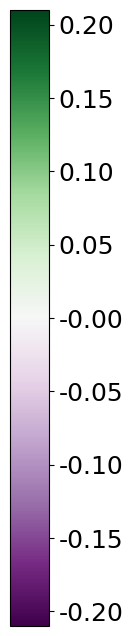

In [29]:
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.colorbar import ColorbarBase
import numpy as np

fig, cax = plt.subplots(figsize=(0.5, 8))

norm = TwoSlopeNorm(
    vmin=-0.21,
    vcenter=0,
    vmax=0.21,
)

cbar = ColorbarBase(
    cax,
    cmap=plt.get_cmap("PRGn"),
    norm=norm,
    ticklocation="right",
    orientation="vertical",
)

ticks = list(np.arange(-0.2, 0.25, 0.05))

cbar.set_ticks(ticks, labels=[f"{t:.2f}" for t in ticks], fontsize=18)

plt.show()

In [10]:
M

array([[        nan,  0.13991346, -0.0207534 ,  0.02362291,  0.02054424],
       [ 0.13519535,         nan, -0.05881252, -0.06131791, -0.06624934],
       [-0.02237601, -0.06562372,         nan,  0.05285632,  0.05304906],
       [ 0.01561957, -0.04195858,  0.03241449,         nan,  0.13834149],
       [ 0.01269384, -0.04236255,  0.03040095,  0.12927649,         nan]])